Assignment 16 by Chris

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


Shape: (1338, 7) 
Missing values:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


,age,bmi,charges
count,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,13270.422265
std,14.049960,6.098187,12110.011237
min,18.000000,15.960000,1121.873900
25%,27.000000,26.296250,4740.287150
50%,39.000000,30.400000,9382.033000
75%,51.000000,34.693750,16639.912515
max,64.000000,53.130000,63770.428010


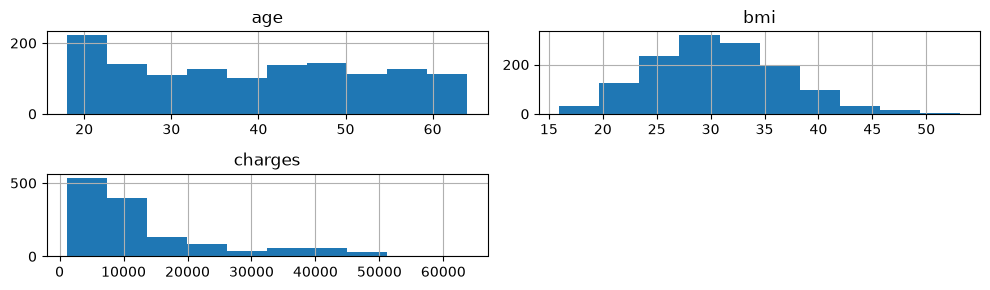

Actual charges median: 9382.03


,Accuracy,Precision,Recall,F1,ROC AUC
Version,,,,,
Unscaled,0.935,0.964,0.779,0.862,0.91
Scaled,0.935,0.964,0.779,0.862,0.91


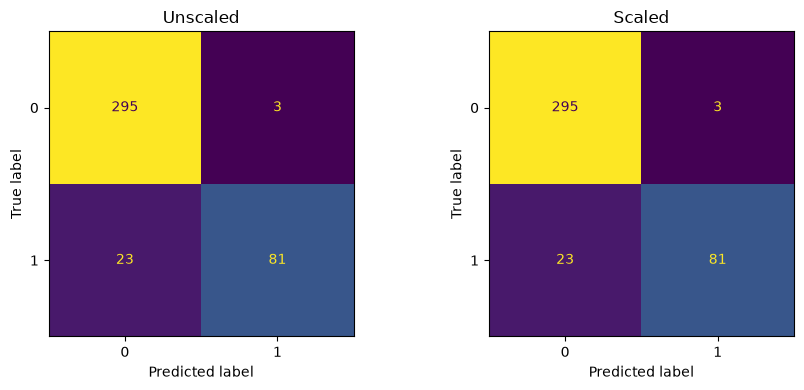

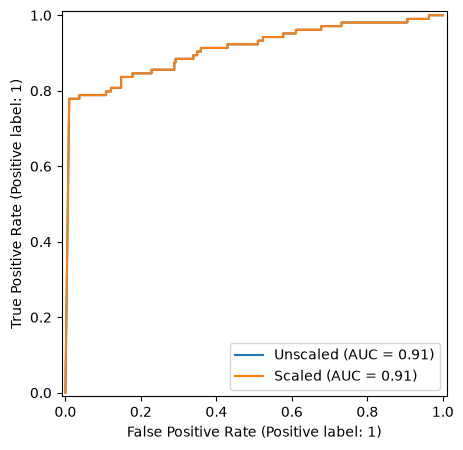

Unscaled: 3 false positives, 23 false negatives.
Scaled: 3 false positives, 23 false negatives.
Compare the F1 and ROC AUC scores above; scaling helps only if those scores improve.


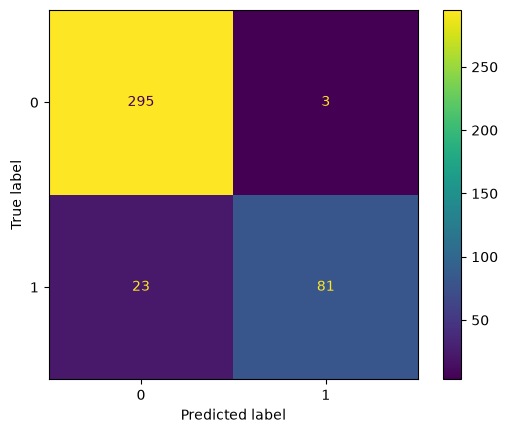

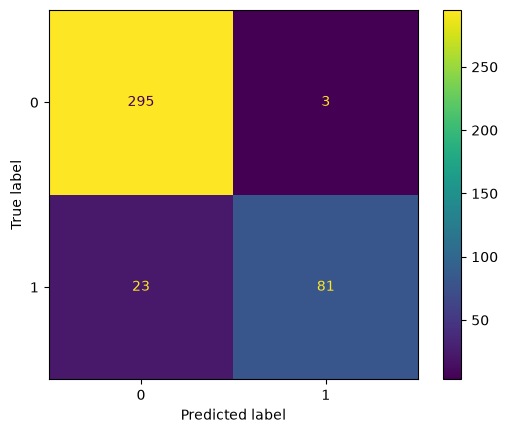

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay

# Load and explore the dataset in the workspace root.
data = pd.read_csv("insurance charges.csv")
display(data.head())
print("Shape:", data.shape, "\nMissing values:\n", data.isna().sum())
display(data[["age", "bmi", "charges"]].describe())
data[["age", "bmi", "charges"]].hist(figsize=(10, 3))
plt.tight_layout()
plt.show()

# Use the assignment's $16,000 cutoff (the dataset's actual median is different).
print("Actual charges median:", round(data["charges"].median(), 2))
data["high_charge"] = (data["charges"] > 16000).astype(int)
X = data[["age", "bmi", "children", "sex", "smoker", "region"]]
y = data["high_charge"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

numeric = ["age", "bmi", "children"]
categorical = ["sex", "smoker", "region"]
models, results = {}, []
for scale in [False, True]:
    num_pipe = make_pipeline(SimpleImputer(strategy="median"))
    if scale:
        num_pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
    prep = ColumnTransformer([
        ("num", num_pipe, numeric),
        ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                               OneHotEncoder(handle_unknown="ignore", sparse_output=False)), categorical),
    ])
    name = "Scaled" if scale else "Unscaled"
    model = make_pipeline(prep, GaussianNB()).fit(X_train, y_train)
    models[name] = model
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    results.append({"Version": name, "Accuracy": accuracy_score(y_test, pred),
                    "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
                    "F1": f1_score(y_test, pred), "ROC AUC": roc_auc_score(y_test, prob)})

display(pd.DataFrame(results).set_index("Version").round(3))

# Confusion matrices and ROC curves for both versions.
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
plt.show()

# Compare false positives (predicted high, actually low) and false negatives.
for name, model in models.items():
    tn, fp, fn, tp = ConfusionMatrixDisplay.from_estimator(model, X_test, y_test).confusion_matrix.ravel()
    print(f"{name}: {fp} false positives, {fn} false negatives.")
print("Compare the F1 and ROC AUC scores above; scaling helps only if those scores improve.")